# Исходный выполненный baseline
Ячейки 23–28 из 01_data_exploration.ipynb с сохранёнными выводами. Код и вывод не менялись; новые запуски здесь не выполнялись. Источник: libfile_21200dc1ade88191a8971e4c4231c1a3.


In [2]:
import torch
from monai.networks.nets import ViT
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device:", device)

# Скачиваем публичную копию pretrained weights
checkpoint_path = hf_hub_download(
    repo_id="eugenehp/brainiac",
    filename="backbone.safetensors"
)

# Архитектура из официального BrainIAC
model = ViT(
    in_channels=1,
    img_size=(96, 96, 96),
    patch_size=(16, 16, 16),
    hidden_size=768,
    mlp_dim=3072,
    num_layers=12,
    num_heads=12,
    spatial_dims=3,
    classification=False,
    save_attn=True
)

state = load_file(checkpoint_path, device="cpu")

# Допускаем префикс backbone. в именах весов
if any(k.startswith("backbone.") for k in state):
    state = {
        k.removeprefix("backbone."): v
        for k, v in state.items()
    }

# Строгая проверка: все параметры должны загрузиться

# Загружаем веса с проверкой совместимости
result = model.load_state_dict(state, strict=False)

# Допустимы только отсутствующие параметры
# неиспользуемой cross-attention нормализации
allowed_missing = {
    f"blocks.{i}.norm_cross_attn.{name}"
    for i in range(12)
    for name in ("weight", "bias")
}

missing = set(result.missing_keys)
unexpected = set(result.unexpected_keys)

assert missing.issubset(allowed_missing), (
    f"Неожиданные отсутствующие параметры: {missing - allowed_missing}"
)
assert not unexpected, (
    f"Лишние параметры checkpoint: {unexpected}"
)

print("Weights loaded successfully!")
print("Missing unused parameters:", len(missing))

model = model.to(device)
model.eval()

for p in model.parameters():
    p.requires_grad_(False)

print("BrainIAC is ready!")

model = model.to(device)
model.eval()

for p in model.parameters():
    p.requires_grad_(False)

print("BrainIAC pretrained weights loaded!")
print("Parameters:", sum(p.numel() for p in model.parameters()))


Device: cpu
Weights loaded successfully!
Missing unused parameters: 24
BrainIAC is ready!
BrainIAC pretrained weights loaded!
Parameters: 88359168


In [3]:

from pathlib import Path
import pandas as pd
import numpy as np

DATA_DIR = Path("data")

tsv_path = Path("participants.tsv")
if not tsv_path.exists():
    tsv_path = DATA_DIR / "participants.tsv"

df = pd.read_csv(
    tsv_path,
    sep="\t",
    dtype={"participant_id": str}
)

df["group"] = df["group"].str.strip().str.upper()
df = df[df["group"].isin(["HC", "ULD"])].copy()

rows = []

for _, row in df.iterrows():
    subject_id = row["participant_id"]
    files = sorted(
        (DATA_DIR / subject_id / "anat").glob("*_T1w.nii*")
    )

    if not files:
        print("Missing:", subject_id)
        continue

    rows.append({
        "id": subject_id,
        "path": str(files[0]),
        "label": int(row["group"] == "ULD")
    })

subjects = pd.DataFrame(rows)

print("Subjects:", len(subjects))
print("HC:", (subjects.label == 0).sum())
print("ULD:", (subjects.label == 1).sum())

display(subjects.head())

Subjects: 66
HC: 37
ULD: 29


,id,path,label
0,sub-C01710,data\sub-C01710\anat\sub-C01710_T1w.nii.gz,0
1,sub-C01713,data\sub-C01713\anat\sub-C01713_T1w.nii.gz,0
2,sub-C01715,data\sub-C01715\anat\sub-C01715_T1w.nii.gz,0
3,sub-C01718,data\sub-C01718\anat\sub-C01718_T1w.nii.gz,0
4,sub-C01719,data\sub-C01719\anat\sub-C01719_T1w.nii.gz,0


In [4]:

from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Orientationd,
    Resized,
    NormalizeIntensityd,
    ToTensord
)

preprocess = Compose([
    LoadImaged(keys=["image"]),
    EnsureChannelFirstd(keys=["image"]),
    Orientationd(keys=["image"], axcodes="RAS"),
    Resized(
        keys=["image"],
        spatial_size=(96, 96, 96),
        mode="trilinear"
    ),
    NormalizeIntensityd(
        keys=["image"],
        nonzero=True,
        channel_wise=True
    ),
    ToTensord(keys=["image"])
])

# Проверка на одном участнике
sample = preprocess({"image": subjects.iloc[0]["path"]})
x = sample["image"].unsqueeze(0).float()

print("Input shape:", x.shape)
print("Mean:", x.mean().item())
print("Std:", x.std().item())


C:\Users\radal\anaconda3\envs\dystonia-mri\Lib\site-packages\monai\utils\deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


Input shape: torch.Size([1, 1, 96, 96, 96])
Mean: 0.0
Std: 0.8194603323936462


In [5]:

from tqdm.auto import tqdm

X = []
y = []
used_ids = []

model.eval()

for _, row in tqdm(
    subjects.iterrows(),
    total=len(subjects),
    desc="Extracting BrainIAC features"
):
    try:
        sample = preprocess({"image": row["path"]})

        x = (
            sample["image"]
            .unsqueeze(0)
            .float()
            .to(device)
        )

        with torch.inference_mode():
            output, _ = model(x)
            embedding = output[:, 0, :]

        features = embedding.cpu().numpy().ravel()

        if not np.isfinite(features).all():
            raise ValueError("Non-finite features")

        X.append(features)
        y.append(int(row["label"]))
        used_ids.append(row["id"])

    except Exception as e:
        print(f"Error: {row['id']} — {e}")

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y, dtype=int)

print("X shape:", X.shape)
print("y shape:", y.shape)

np.savez_compressed(
    "brainiac_uld_hc_embeddings.npz",
    X=X,
    y=y,
    ids=np.asarray(used_ids)
)

Extracting BrainIAC features: 100%|██████████| 66/66 [13:59<00:00, 12.71s/it]

X shape: (66, 768)
y shape: (66,)


In [6]:

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict
)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

assert len(X) > 0 and len(np.unique(y)) == 2
assert min(np.bincount(y)) >= 5

clf = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=0.1,
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    )
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Каждое предсказание получено моделью,
# которая не обучалась на этом участнике
y_proba = cross_val_predict(
    clf, X, y,
    cv=cv,
    method="predict_proba"
)[:, 1]

y_pred = (y_proba >= 0.5).astype(int)

print("Accuracy:",
      round(accuracy_score(y, y_pred), 3))
print("Balanced accuracy:",
      round(balanced_accuracy_score(y, y_pred), 3))
print("ROC-AUC:",
      round(roc_auc_score(y, y_proba), 3))

print("\nClassification report:")
print(classification_report(
    y, y_pred,
    target_names=["HC", "ULD"],
    zero_division=0
))

print("\nConfusion matrix:")
print(confusion_matrix(y, y_pred))


Accuracy: 0.576
Balanced accuracy: 0.562
ROC-AUC: 0.569

Classification report:
              precision    recall  f1-score   support

          HC       0.61      0.68      0.64        37
         ULD       0.52      0.45      0.48        29

    accuracy                           0.58        66
   macro avg       0.56      0.56      0.56        66
weighted avg       0.57      0.58      0.57        66


Confusion matrix:
[[25 12]
 [16 13]]


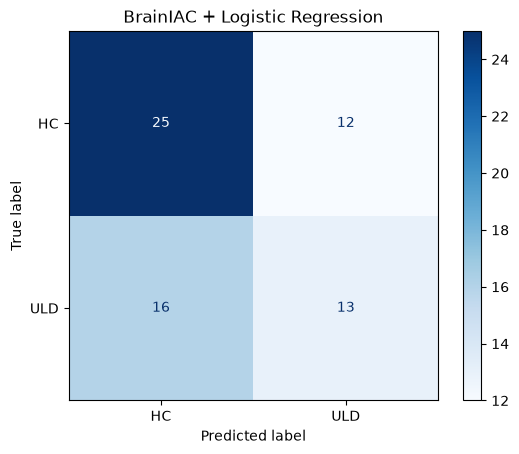

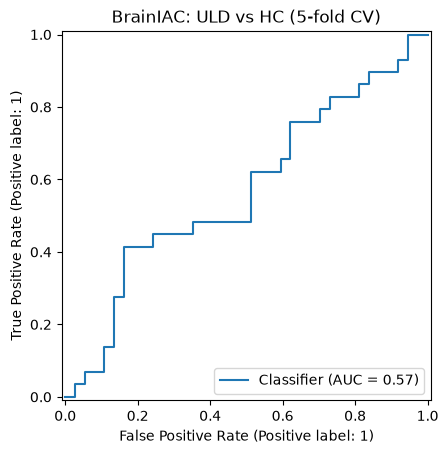

In [7]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

ConfusionMatrixDisplay.from_predictions(
    y, y_pred,
    display_labels=["HC", "ULD"],
    cmap="Blues"
)
plt.title("BrainIAC + Logistic Regression")
plt.show()

RocCurveDisplay.from_predictions(
    y, y_proba
)
plt.title("BrainIAC: ULD vs HC (5-fold CV)")
plt.show()
